# Black-Scholes PIKAN Implementation

Here I implement a Physics-Informed Kolmogorov-Arnold Network for solving the Black-Scholes equation.

In [2]:
import sys
sys.path.append("..")

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import gc
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm
from src.metrics import error_summary
from src.metrics import mse, rmse, mae, max_abs_error, relative_l2_error
import pandas as pd

torch.set_num_threads(1)

from src.analytical import black_scholes_call_grid, call_price
from src.pikan import BlackScholesPIKAN
from src.training_points import generate_training_points
from src.losses import black_scholes_pde_loss
from src.evaluation import evaluate_model_on_grid, compute_metric_row

torch.manual_seed(42)
np.random.seed(42)


In [3]:
# Defining parameters. Note I am using the same parameters as in the PINN notebook for consistency.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [9]:
# Training the PIKAN model.

model_pikan = BlackScholesPIKAN(
    layers=[2, 16, 16, 1],
    grid=5,
    degree=3,
    S_max=S_max,
    T=T,
    seed=42
)

model_pikan.train()

optimizer = torch.optim.Adam(model_pikan.parameters(), lr=1e-3)

loss_history = []

epochs = 3000

N_f = 300
N_ic = 150
N_bc = 150

def train_step():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_pikan,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.092773e+00, PDE=9.262727e-08, IC=9.937017e-01, LB=3.771991e-08, UB=4.099071e+00
Epoch 500: Total=1.500672e-01, PDE=5.215966e-03, IC=7.265426e-03, LB=2.996876e-06, UB=1.375828e-01
Epoch 1000: Total=1.505434e-04, PDE=9.265407e-05, IC=3.471211e-05, LB=3.845535e-07, UB=2.279271e-05
Epoch 1500: Total=4.160508e-05, PDE=2.797901e-05, IC=1.026977e-05, LB=2.143801e-08, UB=3.334859e-06
Epoch 2000: Total=2.110333e-05, PDE=1.239429e-05, IC=8.113359e-06, LB=1.319321e-08, UB=5.824874e-07
Epoch 2500: Total=1.560309e-05, PDE=6.782084e-06, IC=8.545543e-06, LB=8.279105e-09, UB=2.671871e-07


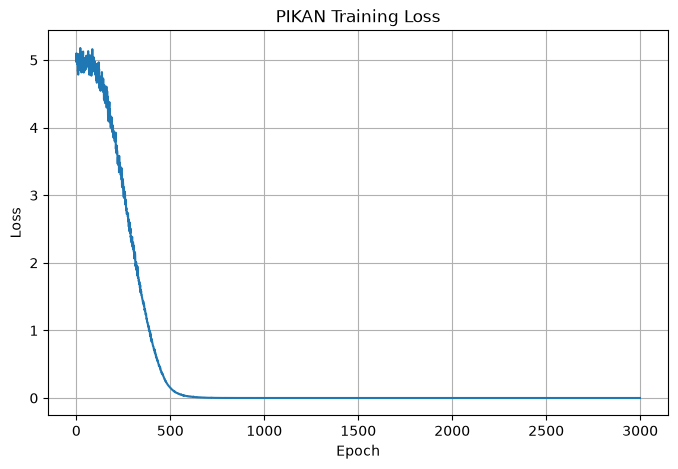

In [10]:
# Plotting the loss.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PIKAN Training Loss")
plt.grid()
plt.show()

In [11]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PIKAN on the full grid
model_pikan.eval()
with torch.no_grad():
    V_pred = model_pikan(S_flat, tau_flat)

V_surface_pikan = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

# Comparing PIKAN predictions with the exact Black-Scholes solution
V_exact_surface = black_scholes_call_grid(S_grid_np,tau_grid_np,K,r,sigma)
abs_error_surface_pikan = np.abs(V_surface_pikan - V_exact_surface)

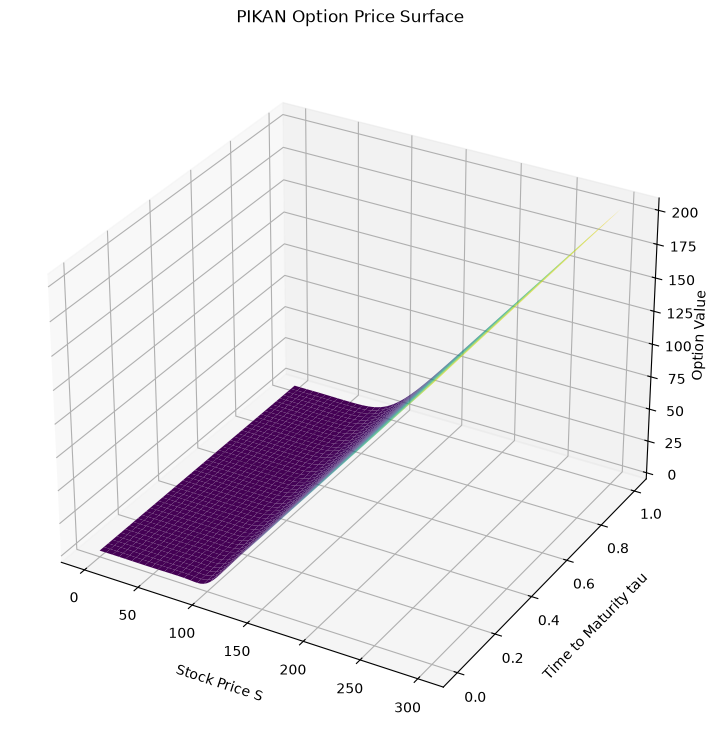

In [12]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_surface_pikan, cmap="viridis")

ax.set_title("PIKAN Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

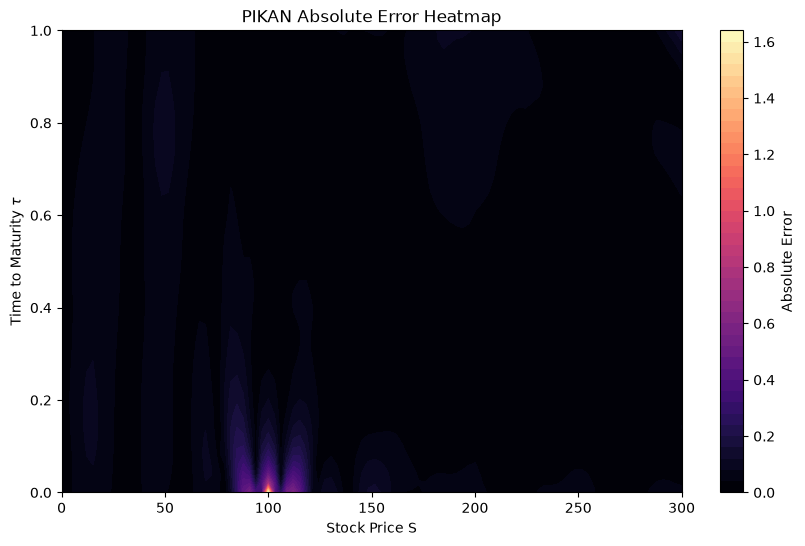

In [13]:
# Now, plot the absolute error heatmap between the PIKAN predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_pikan, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PIKAN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [14]:
# Plotting some key metrics for a more quantitative assessment of the cPIKAN's performance against the analytical solution.

metrics = error_summary(V_surface_pikan, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.003373
1,RMSE,0.058075
2,MAE,0.033826
3,Max Abs Error,1.629618
4,Relative L2 Error,0.000601


In [15]:
# Defining a function that counts the number of trainable parameters in a given model architecture.
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model_pikan)

4256

## PIKAN tuning

The PIKAN performs well but with a long runtime. Note that according to the loss curve it doesn't seem as if 3000 epochs is necessary. I will run one more experiment with 1000 epochs, as this seems to be around where the loss curve settles.

In [4]:
# Training the PIKAN model with fewer epochs.

model_pikan_short = BlackScholesPIKAN(
    layers=[2, 16, 16, 1],
    grid=5,
    degree=3,
    S_max=S_max,
    T=T,
    seed=42
)

model_pikan_short.train()

optimizer = torch.optim.Adam(model_pikan_short.parameters(), lr=1e-3)

loss_history = []

epochs = 1000

N_f = 300
N_ic = 150
N_bc = 150

def train_step():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_pikan_short,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.092773e+00, PDE=9.262727e-08, IC=9.937017e-01, LB=3.771991e-08, UB=4.099071e+00
Epoch 500: Total=1.500672e-01, PDE=5.215966e-03, IC=7.265426e-03, LB=2.996876e-06, UB=1.375828e-01


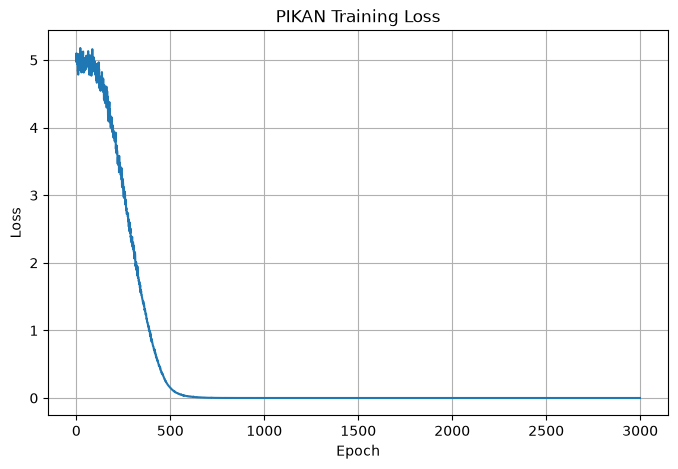

In [16]:
# Plotting the loss.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PIKAN Training Loss")
plt.grid()
plt.show()

In [17]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PIKAN on the full grid
model_pikan_short.eval()
with torch.no_grad():
    V_pred = model_pikan_short(S_flat, tau_flat)

V_surface_pikan_short = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

# Comparing PIKAN predictions with the exact Black-Scholes solution
abs_error_surface_pikan_short = np.abs(V_surface_pikan_short - V_exact_surface)

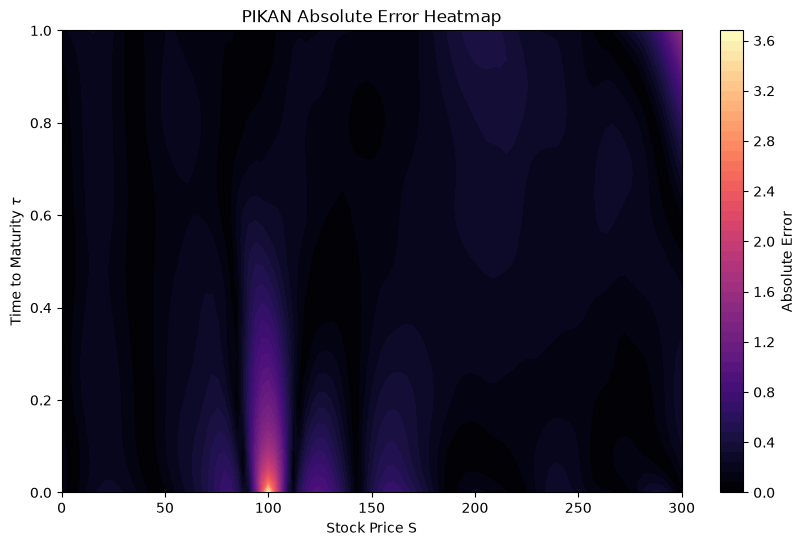

In [18]:
# Now, plot the absolute error heatmap between the PIKAN (with fewer epochs) predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_pikan_short, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PIKAN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [19]:
# Plotting some key metrics for a more quantitative assessment of the PIKAN's performance against the analytical solution.

metrics = error_summary(V_surface_pikan_short, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.082062
1,RMSE,0.286464
2,MAE,0.204735
3,Max Abs Error,3.646942
4,Relative L2 Error,0.002964


The relative error here as well as the maximum absolute error is higher that the original PIKAN trained with 3000 epochs. This indicates that the loss curve might not tell the full story.

Despite the considerably longer runtime I will use the 3000 epoch PIKAN in comparision with the PINNs as it has smller errors across the board. Note however that the PIKAN trained on 1000 epochs performed sightly better than the "best" PINN in most metrics with slightly longer runtime.